[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.1/Problem_1.17.ipynb)

# Chapter 1, Problem 17 — the pole-in-the-barn paradox

**Problem (paraphrased).** A lightweight pole 20 m long lies on the ground next to a barn 15 m long. An athlete picks it up, carries it far away, and runs with it toward the end of the barn at $0.8c$. His friend stays at rest by the barn door.

- **(a)** How long does the friend measure the pole to be as it approaches?
- **(b)** The door is initially open; immediately after the runner and pole are entirely inside, the friend shuts the door. How long after that does the front of the pole hit the other end of the barn, as measured by the friend? Compute the interval between shutting the door and hitting the wall. Spacelike, timelike or null?
- **(c)** In the runner's frame, what are the lengths of the barn and the pole?
- **(d)** Does the runner believe the pole is entirely inside the barn when its front hits the end? Explain.
- **(e)** After the collision the pole and runner come to rest relative to the barn. From the friend's view, the 20 m pole is now inside a 15 m barn, since the door was shut before the pole stopped. How? From the runner's view, the collision should have stopped the pole before the door closed, so the door couldn't be closed at all. Was the door closed with the pole inside or not?
- **(f)** Draw a spacetime diagram from the friend's point of view to illustrate and justify everything.

**Coordinates.** Friend/barn frame $\mathcal O$: door at $x = 0$, far wall at $x = 15$ m, runner moving in $+x$. Runner frame $\bar{\mathcal O}$ with $v = 0.8$:
$$
\gamma = \frac{1}{\sqrt{1 - 0.64}} = \frac{1}{0.6} = \frac53 .
$$
Choose $t = 0$ at the moment the **back** of the pole passes the door.

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

In [2]:
import numpy as np
import sympy as sp
from schutz_gr import gamma, lorentz, inverse_lorentz, interval_tx
from schutz_gr.diagrams import SpacetimeDiagram, COLORS
%config InlineBackend.figure_format = 'retina'
R = sp.Rational
v = R(4, 5); g = gamma(v)
Lpole, Lbarn = 20, 15
print("γ =", g)

γ = 5/3


## (a) Length of the pole in the friend's frame

The pole is at rest in $\bar{\mathcal O}$ with proper length 20 m. Lorentz contraction (Eq. 1.11):
$$
L_{\mathcal O} = \frac{20\ \text{m}}{\gamma} = 20\times0.6 = \boxed{12\ \text{m}}
$$

## (b) Door-shutting and wall-hitting, in the friend's frame

**World lines.** Back of pole: $x_b(t) = 0.8\,t$ (at the door at $t = 0$). Front: $x_f(t) = 0.8\,t + 12$.

**Event S — door shut.** "Immediately after" the pole is fully inside means as the back passes the door: $\boxed{S = (t, x) = (0,\ 0)}$. At that moment the front is at $x = 12$, i.e. 3 m short of the wall. The 12 m pole fits in the 15 m barn with room to spare.

**Event H — front hits the far wall.** $x_f = 15 \Rightarrow 0.8t = 3 \Rightarrow t = 3.75$ m:
$$
\boxed{H = (3.75,\ 15)},\qquad \Delta t_{SH} = 3.75\ \text{m} = \frac{3.75}{3\times10^{8}}\ \text{s} = 12.5\ \text{ns}.
$$

**Interval.**
$$
\Delta s^2_{SH} = -(3.75)^2 + (15)^2 = -14.0625 + 225 = \boxed{+210.94\ \text{m}^2} > 0\quad\Rightarrow\quad\textbf{spacelike}.
$$
That's the crux of the paradox. S and H are spacelike separated, so (i) neither can causally influence the other, and (ii) different observers can disagree on their time order.

In [3]:
S = (R(0), R(0))
H = (R(3, 1) / v, R(15))
print("S =", S, "  H =", H, " (t_H =", float(H[0]), "m =", float(H[0]) / 3e8 * 1e9, "ns)")
print("Δs²(S,H) =", interval_tx(H[0] - S[0], H[1] - S[1]), "=", float(interval_tx(H[0] - S[0], H[1] - S[1])))

S = (0, 0)   H = (15/4, 15)  (t_H = 3.75 m = 12.5 ns)
Δs²(S,H) = 3375/16 = 210.9375


## (c) Lengths in the runner's frame

Now the pole is at rest (proper length) and the barn moves at $-0.8$, so the barn is contracted:
$$
\text{pole: } \boxed{20\ \text{m}},\qquad \text{barn: } \frac{15}{\gamma} = 15\times0.6 = \boxed{9\ \text{m}}.
$$
For the runner a 20 m pole is heading into a 9 m barn — it obviously can't "fit".

## (d) Does the runner think the pole is inside when the front hits the wall?

**No.** Transform S and H into $\bar{\mathcal O}$ ($\bar t = \gamma(t - vx)$, $\bar x = \gamma(x - vt)$):
$$
S:\ \bar t = 0,\ \bar x = 0;\qquad
H:\ \bar t = \tfrac53(3.75 - 0.8\times15) = \tfrac53(-8.25) = -13.75,\quad \bar x = \tfrac53(15 - 0.8\times3.75) = \tfrac53(12) = 20 .
$$
- $\bar x_H = 20$: the front of the pole, 20 m from the back ✓.
- $\bar t_H = -13.75 < 0 = \bar t_S$: **for the runner, the front hits the wall 13.75 m of time *before* the door is shut.**

Where is the back of the pole (at rest at $\bar x = 0$) relative to the door at that moment? The door moves at $-0.8$ and passes $\bar x = 0$ at $\bar t = 0$, so at $\bar t = -13.75$ it's at $\bar x = 0.8\times13.75 = 11$ m. The back is 11 m outside the door. (Check: the wall is 9 m beyond the door, at $\bar x = 20$ ✓.)

**Why.** "The whole pole is inside the barn" means "both ends are inside at the same time". That's a statement about simultaneity, and the two observers' lines of simultaneity differ. The friend's "now" at $t = 0$ catches the back at the door and the front 3 m short of the wall. The runner's "now" through H catches the front at the wall and the back 11 m outside. Both are correct in their own frames: S and H are spacelike separated, so their time order is frame-dependent.

In [4]:
for name, ev in (("S", S), ("H", H)):
    tb, xb = (sp.nsimplify(q) for q in lorentz(*ev, v))
    print(f"{name}: (t̄, x̄) = ({tb}, {xb})")
tbH = lorentz(*H, v)[0]
print("door position in Ō at t̄_H:", -v * tbH, "m  (back of pole at x̄ = 0)")

S: (t̄, x̄) = (0, 0)
H: (t̄, x̄) = (-55/4, 20)
door position in Ō at t̄_H: 11 m  (back of pole at x̄ = 0)


## (e) Was the door closed with the pole inside?

**Yes** — and the pole does *not* survive as a 20 m rigid rod. The resolution is that **there are no rigid bodies in relativity**.

When the front hits the wall (H), the back of the pole has no way of knowing it. The "stop" signal is a compression wave in the pole. It can travel back along the pole at most at the speed of light, and in a real material far slower. Until the signal arrives, the back keeps moving at 0.8. So the pole gets compressed or crushed.

**In the friend's frame.** Take the fastest possible signal, speed 1 in $-x$ from H: $x = 15 - (t - 3.75)$. The back, $x = 0.8t$, receives it at event R:
$$
0.8t = 18.75 - t \;\Rightarrow\; t_R = \frac{18.75}{1.8} = 10.42\ \text{m},\qquad x_R = 8.33\ \text{m}.
$$
So the back of the pole stops at $x \geq 8.33$ m (a slower signal means it stops even farther in). The pole ends up at rest in the barn, compressed to at most $15 - 8.33 = 6.67$ m. The door was shut at $t = 0$, behind the back. The friend's picture is consistent: the door closed with the pole inside, and the pole was squashed against the wall. (Whatever happens next — the pole springs back and breaks the door, or shatters — is materials science, not relativity.)

**In the runner's frame.** The front stops at H ($\bar t = -13.75$, $\bar x = 20$). The signal travels back at most at speed 1 and reaches $\bar x = 0$ at $\bar t \geq -13.75 + 20 = 6.25$. Until then the back hasn't "heard", so it stays at rest at $\bar x = 0$ while the barn rushes toward it at 0.8. At $\bar t = 0$ the door reaches the back — event S — and is shut. That's 6.25 m of time *before* the back could possibly start to move. The runner's objection, "the collision stopped the pole before the door closed", assumes the whole pole stops at the instant the front does, i.e. a stop signal faster than light. Without that assumption the runner agrees: the door shuts behind the pole, and the pole is then crushed.

**Both frames agree** on every physical coincidence: the door shuts as it passes the back of the pole (S); the front hits the wall (H); the back stops at R. Transforming R: $(\bar t, \bar x) = (6.25, 0)$ ✓ — the same event in both descriptions.

In [5]:
t = sp.symbols("t")
tR = sp.solve(sp.Eq(v*t, 15 - (t - H[0])), t)[0]
Rev = (tR, v*tR)
print("R (back receives stop signal, signal at c): t =", tR, "≈", float(tR), "  x =", Rev[1], "≈", float(Rev[1]))
print("compressed length at most:", 15 - Rev[1], "≈", float(15 - Rev[1]), "m")
print("R in runner frame:", tuple(sp.nsimplify(q) for q in lorentz(*Rev, v)))

R (back receives stop signal, signal at c): t = 125/12 ≈ 10.416666666666666   x = 25/3 ≈ 8.333333333333334
compressed length at most: 20/3 ≈ 6.666666666666667 m
R in runner frame: (25/4, 0)


## (f) Spacetime diagram — friend's frame

The diagram below shows, in $\mathcal O$'s coordinates:
- the barn: door world line $x = 0$ and wall $x = 15$ (grey), with the door drawn as *closed* (solid) from S onward;
- the pole's two ends moving at 0.8, contracted to 12 m (green). The back continues until it receives the stop signal at R;
- the fastest possible stop signal from H back to R (gold, at 45°);
- the friend's line of simultaneity through S ($t = 0$, teal), which shows the pole fully inside;
- the runner's line of simultaneity through H ($\bar t = -13.75$, amber, slope 0.8), which shows the back still outside the barn when the front hits;
- the runner's line of simultaneity through S ($\bar t = 0$, dotted amber), which shows the front already at the wall long before the door shuts.

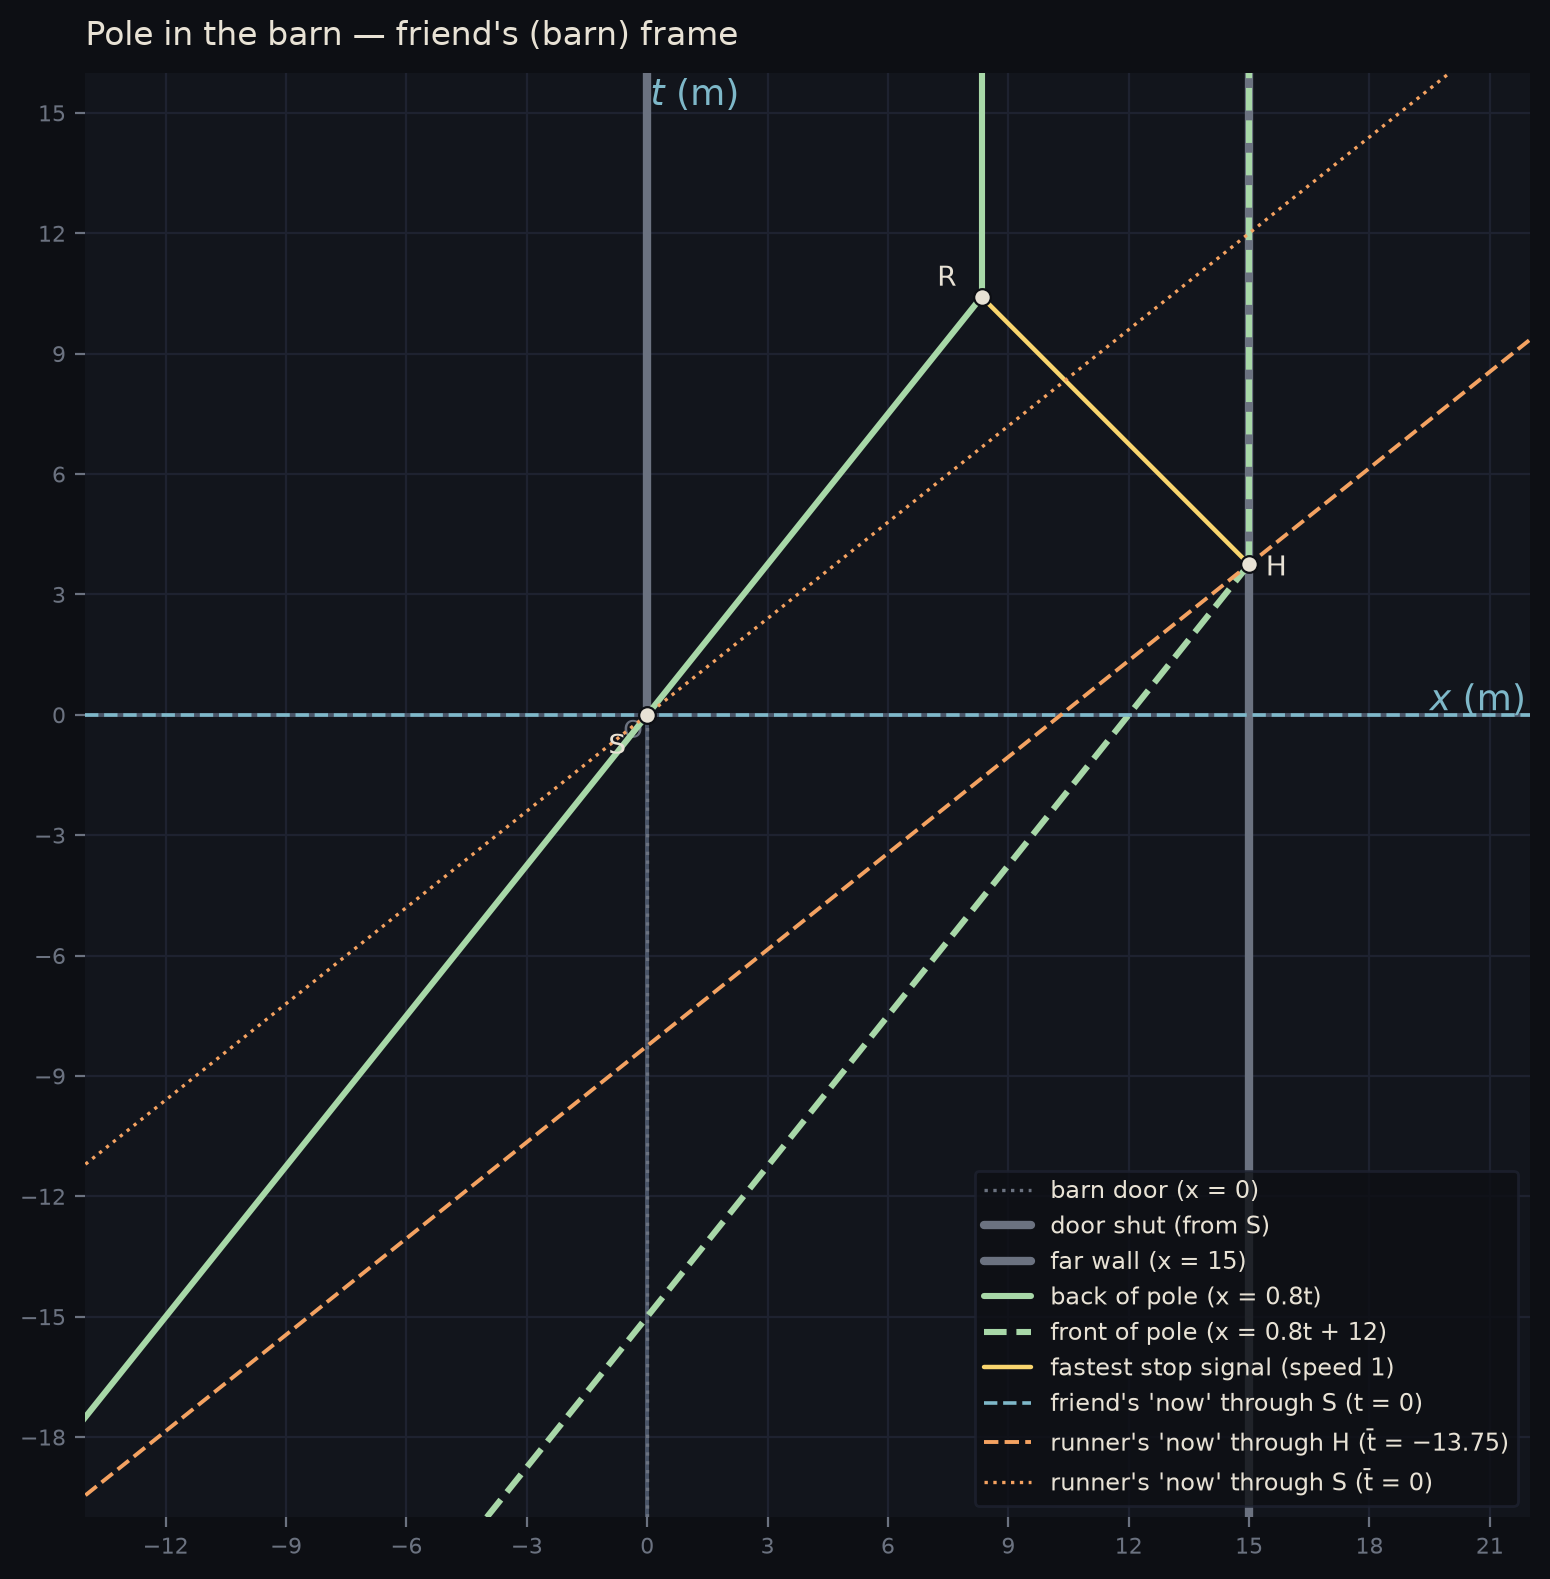

back of pole on the runner's simultaneity line through H: t = -22.92, x = -18.33 (outside the door, x < 0)


In [6]:
vf, gf = 0.8, 5/3
d = SpacetimeDiagram(xlim=(-14, 22), tlim=(-20, 16), title="Pole in the barn — friend's (barn) frame", size=8)
d.ax.set_xticks(range(-12, 23, 3)); d.ax.set_yticks(range(-18, 16, 3))
T = np.array([-20, 16.0])
d.line([0, 0], T, color="grey", lw=1.2, ls=":", label="barn door (x = 0)")
d.line([0, 0], [0, 16], color="grey", lw=3.0, label="door shut (from S)")
d.line([15, 15], T, color="grey", lw=3.0, label="far wall (x = 15)")
tH, tR = 3.75, 18.75/1.8
Tb = np.linspace(-20, tR, 50)
d.line(vf*Tb, Tb, color="green", lw=2.2, label="back of pole (x = 0.8t)")
d.line([vf*tR, vf*tR], [tR, 16], color="green", lw=2.2)
Tf = np.linspace(-20, tH, 50)
d.line(vf*Tf + 12, Tf, color="green", lw=2.2, ls="--", label="front of pole (x = 0.8t + 12)")
d.line([15, 15], [tH, 16], color="green", lw=2.2, ls="--")
d.line([15, vf*tR], [tH, tR], color="gold", lw=1.6, label="fastest stop signal (speed 1)")
X = np.linspace(-14, 22, 2)
d.line(X, 0*X, color="teal", lw=1.3, ls="--", label="friend's 'now' through S (t = 0)")
d.line(X, tH + vf*(X - 15), color="amber", lw=1.4, ls="--", label="runner's 'now' through H (t̄ = −13.75)")
d.line(X, vf*X, color="amber", lw=1.2, ls=":", label="runner's 'now' through S (t̄ = 0)")
d.event(0, 0, name="S", offset=(-14, -14))
d.event(tH, 15, name="H", offset=(6, -4))
d.event(tR, vf*tR, name="R", offset=(-16, 4))
tb_back = tH + vf*(0 - 15) + 0       # runner-simultaneous with H at the pole's back: intersect x = 0.8t with the H line
t_back = (tH - vf*15) / (1 - vf**2)
d.event(t_back, vf*t_back, name="back, 'when' H (runner)", offset=(-150, 0))
d.show(loc="lower right")
print(f"back of pole on the runner's simultaneity line through H: t = {t_back:.2f}, x = {vf*t_back:.2f} (outside the door, x < 0)")

## Summary

| | friend (barn frame) | runner (pole frame) |
|---|---|---|
| pole length | 12 m | 20 m |
| barn length | 15 m | 9 m |
| door shut S | $t = 0$ | $\bar t = 0$ |
| front hits wall H | $t = 3.75$ m (after S) | $\bar t = -13.75$ m (before S) |
| $\Delta s^2_{SH}$ | $+210.94$ m² | $+210.94$ m² (spacelike) |

The "paradox" dissolves on two points: (1) "entirely inside" is a simultaneity statement, and simultaneity is frame-dependent for spacelike-separated events; (2) a pole can't stop all at once, because no signal is faster than light. In every frame the door shuts behind the pole and the pole is then crushed inside the barn.